# 03 · Modelado

Se comparan tres modelos: **Regresión logística, Árbol de decisión y Random Forest**.

- La comparación se hace con **validación cruzada estratificada (5 folds) solo sobre train**.
  El conjunto de test no se usa en este notebook.
- Métricas: **ROC-AUC, PR-AUC** y **Recall / Precision / F1** en el umbral que maximiza F1.
- La imputación y el encoding están dentro del `Pipeline`, así que se ajustan en cada fold.

In [1]:
import json
import time

import numpy as np
import pandas as pd

from src.data import load_dataset, split_train_test
from src.evaluation import compute_metrics
from src.features import engineer
from src.models import CV, best_f1_threshold, cv_evaluate, get_models

pd.set_option("display.width", 140)
X, y = load_dataset()
X = engineer(X)
X_train, X_test, y_train, y_test = split_train_test(X, y)
del X_test, y_test  # el test no se usa en este notebook
print("train:", X_train.shape, f"| positivos {y_train.mean():.2%}")

train: (55978, 43) | positivos 8.97%


## 1. Validación cruzada de los modelos

In [2]:
models = get_models()
results, oof_store = [], {}


def evaluate(name, model):
    t = time.time()
    folds, oof = cv_evaluate(model, X_train, y_train, CV)
    thr = best_f1_threshold(y_train, oof)
    m = compute_metrics(y_train, oof, thr)
    results.append(
        {
            "modelo": name,
            "roc_auc": folds["roc_auc"].mean(),
            "roc_auc_std": folds["roc_auc"].std(),
            "pr_auc": folds["pr_auc"].mean(),
            "pr_auc_std": folds["pr_auc"].std(),
            "recall": m["recall"],
            "precision": m["precision"],
            "f1": m["f1"],
            "umbral": thr,
            "seg": round(time.time() - t),
        }
    )
    oof_store[name] = oof
    print(f"{name:<14} ROC-AUC {folds['roc_auc'].mean():.4f}  PR-AUC {folds['pr_auc'].mean():.4f}"
          f"  Recall {m['recall']:.3f}  F1 {m['f1']:.3f}  (umbral {thr:.2f}, {results[-1]['seg']} s)")


for name, model in models.items():
    evaluate(name, model)

LogReg         ROC-AUC 0.6484  PR-AUC 0.1646  Recall 0.348  F1 0.228  (umbral 0.58, 26 s)


Árbol          ROC-AUC 0.6216  PR-AUC 0.1490  Recall 0.361  F1 0.209  (umbral 0.56, 10 s)


RandomForest   ROC-AUC 0.6510  PR-AUC 0.1652  Recall 0.460  F1 0.227  (umbral 0.51, 27 s)


## 2. Tabla comparativa y elección del ganador
El ganador es el de mayor **ROC-AUC medio en CV**. PR-AUC se muestra también porque la clase
positiva es solo ~9 %.

In [3]:
res = pd.DataFrame(results)
res["ganador"] = ""
res.loc[res["roc_auc"].idxmax(), "ganador"] = "◄"
print(res.round(4).to_string(index=False))
res

      modelo  roc_auc  roc_auc_std  pr_auc  pr_auc_std  recall  precision     f1  umbral  seg ganador
      LogReg   0.6484       0.0069  0.1646      0.0040  0.3485     0.1697 0.2282    0.58   26        
       Árbol   0.6216       0.0059  0.1490      0.0049  0.3610     0.1467 0.2086    0.56   10        
RandomForest   0.6510       0.0054  0.1652      0.0034  0.4596     0.1509 0.2272    0.51   27       ◄


,modelo,roc_auc,roc_auc_std,pr_auc,pr_auc_std,recall,precision,f1,umbral,seg,ganador
0,LogReg,0.648389,0.006891,0.164566,0.003950,0.348467,0.169689,0.228236,0.58,26,
1,Árbol,0.621566,0.005863,0.149029,0.004869,0.361012,0.146671,0.208595,0.56,10,
2,RandomForest,0.650971,0.005381,0.165161,0.003353,0.459578,0.150869,0.227165,0.51,27,◄


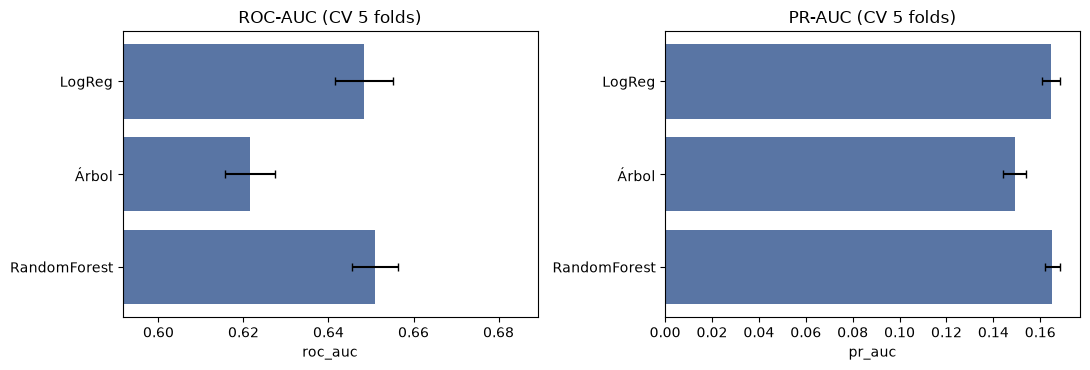

In [4]:
import matplotlib.pyplot as plt  # noqa: E402
import seaborn as sns  # noqa: E402

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, (col, err, title) in zip(ax, [("roc_auc", "roc_auc_std", "ROC-AUC (CV 5 folds)"),
                                      ("pr_auc", "pr_auc_std", "PR-AUC (CV 5 folds)")]):
    sns.barplot(data=res, y="modelo", x=col, ax=a, color="#4c72b0")
    a.errorbar(res[col], range(len(res)), xerr=res[err], fmt="none", c="k", capsize=3)
    a.set_title(title)
    a.set_xlim(res[col].min() - 0.03 if col == "roc_auc" else 0, None)
    a.set_ylabel("")
fig.tight_layout()
fig.savefig("../reports/figures/comparacion_modelos_cv.png", dpi=130)

## 3. Guardar resultados para el notebook 04

In [5]:
win = res.loc[res["roc_auc"].idxmax()]
print("Ganador:", win["modelo"], f"| ROC-AUC {win['roc_auc']:.4f} | umbral {win['umbral']:.2f}")

res.drop(columns="ganador").to_csv("../artifacts/cv_results.csv", index=False)
winner = {
    "modelo": win["modelo"],
    "umbral": float(win["umbral"]),
}
with open("../artifacts/winner.json", "w", encoding="utf-8") as f:
    json.dump(winner, f, indent=2, ensure_ascii=False)
winner

Ganador: RandomForest | ROC-AUC 0.6510 | umbral 0.51


{'modelo': 'RandomForest', 'umbral': 0.5099999999999999}

## Conclusiones
- **Ganador:** Random Forest (ROC-AUC CV ≈ 0.651, PR-AUC ≈ 0.165).
- La diferencia con la regresión logística (0.648) es muy pequeña, menor que la variación entre
  folds (≈ 0.005-0.007), así que en la práctica rinden parecido. El árbol simple es claramente
  peor (0.622).
- Un ROC-AUC de ~0.65 es normal en este dataset: con la información disponible al alta solo se
  explica una parte del reingreso.